# Chapter 12: Probability, Samples and Uncertainty

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 12.1 Probability Distributions as Models

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('book.mplstyle')

orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
survey = pd.read_csv('survey.csv', parse_dates=['response_date'])
cancellations = pd.read_csv('cancellations.csv',
                            parse_dates=['cancel_date'])

age = customers['age'].dropna()
print(f'{len(age):,} ages, mean {age.mean():.2f}, '
      f'standard deviation {age.std():.2f}')

4,043 ages, mean 37.96, standard deviation 10.81


### `stats.norm`

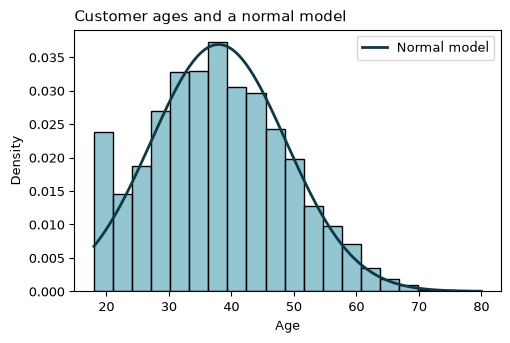

In [2]:
mean_age, sd_age = age.mean(), age.std()
x = np.linspace(18, 80, 200)

ax = sns.histplot(age, binwidth=3, stat='density', color='#6fb3c2')
ax.plot(x, stats.norm.pdf(x, loc=mean_age, scale=sd_age),
        color='#0b3a47', label='Normal model')
ax.legend()
ax.set_title('Customer ages and a normal model')
ax.set_xlabel('Age')
plt.show()

In [3]:
model_under_25 = stats.norm.cdf(25, loc=mean_age, scale=sd_age)
real_under_25 = (age < 25).mean()
print(f'Under 25, model: {model_under_25:.1%}')
print(f'Under 25, real:  {real_under_25:.1%}')

Under 25, model: 11.5%
Under 25, real:  11.7%


In [4]:
model_p90 = stats.norm.ppf(0.9, loc=mean_age, scale=sd_age)
print(f'90th percentile, model: {model_p90:.1f}')
print(f"90th percentile, real:  {age.quantile(0.9):.1f}")

90th percentile, model: 51.8
90th percentile, real:  52.0


In [5]:
fake_ages = stats.norm.rvs(loc=mean_age, scale=sd_age, size=5,
                           random_state=42)
fake_ages.round(1)

array([43.3, 36.5, 45. , 54.4, 35.4])

### `stats.binom`

In [6]:
boxes = orders[orders['order_type'] == 'Subscription'].copy()
boxes['late'] = boxes['delivery_days'] > 5
p_late = boxes['late'].mean()
print(f'{len(boxes):,} boxes, {p_late:.1%} late')

24,252 boxes, 8.8% late


In [7]:
late_counts = np.arange(5)
chances = stats.binom.pmf(late_counts, n=12, p=p_late)
pd.Series(chances, index=late_counts).round(3)

0    0.330
1    0.383
2    0.204
3    0.066
4    0.014
dtype: float64

In [8]:
two_or_more = 1 - stats.binom.cdf(1, n=12, p=p_late)
print(f'Two or more late boxes in a year: {two_or_more:.1%}')

Two or more late boxes in a year: 28.6%


In [9]:
rng = np.random.default_rng(42)
simulated = stats.binom.rvs(n=12, p=p_late, size=10_000,
                            random_state=rng)
print(f'Share with two or more: {(simulated >= 2).mean():.1%}')

Share with two or more: 28.0%


## 12.2 Samples and Populations

In [10]:
amounts = orders.loc[orders['order_type'] == 'Add-on', 'amount']
print(f'Population: {len(amounts):,} add-on orders, '
      f'true average ${amounts.mean():.2f}')

Population: 4,520 add-on orders, true average $25.82


### `df.sample()` with a random number generator

In [11]:
rng = np.random.default_rng(42)
for _ in range(5):
    one_sample = amounts.sample(50, random_state=rng)
    print(f'Average of 50 orders: ${one_sample.mean():.2f}')

Average of 50 orders: $23.79
Average of 50 orders: $21.63
Average of 50 orders: $21.00
Average of 50 orders: $23.38
Average of 50 orders: $20.94


### A random sample and a convenient one

In [12]:
customers = customers.merge(
    cancellations[['customer_id', 'cancel_date', 'reason']],
    on='customer_id', how='left', validate='one_to_one')
end_date = customers['cancel_date'].fillna(pd.Timestamp('2025-12-31'))
days = (end_date - customers['signup_date']).dt.days
customers['tenure_months'] = (days / 30.44).round(1)

first_500 = customers.head(500)
random_500 = customers.sample(500, random_state=42)
print(f"All customers: {customers['tenure_months'].mean():.1f} months")
print(f"First 500:     {first_500['tenure_months'].mean():.1f} months")
print(f"Random 500:    {random_500['tenure_months'].mean():.1f} months")

All customers: 5.3 months
First 500:     8.0 months
Random 500:    5.8 months


## 12.3 How Sample Averages Vary

In [13]:
rng = np.random.default_rng(42)
sample_means = {}
for n in [10, 100, 1000]:
    means = []
    for _ in range(1000):
        means.append(amounts.sample(n, random_state=rng).mean())
    sample_means[n] = pd.Series(means)

for n, means in sample_means.items():
    print(f'{n:>5} orders: averages from ${means.min():.2f} '
          f'to ${means.max():.2f}, skew {means.skew():.2f}')

   10 orders: averages from $13.34 to $120.79, skew 3.60
  100 orders: averages from $19.97 to $40.27, skew 1.02
 1000 orders: averages from $23.08 to $29.20, skew 0.32


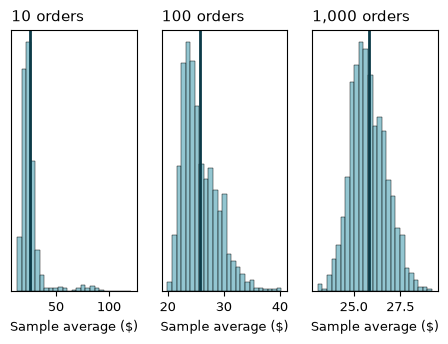

In [14]:
fig, axes = plt.subplots(1, 3)
for ax, n in zip(axes, [10, 100, 1000]):
    sns.histplot(sample_means[n], bins=25, color='#6fb3c2', ax=ax)
    ax.axvline(amounts.mean(), color='#0b3a47')
    ax.set_title(f'{n:,} orders')
    ax.set_xlabel('Sample average ($)')
    ax.set_ylabel('')
    ax.set_yticks([])
plt.show()

## 12.4 Standard Error

In [15]:
delivery = orders['delivery_days']
rng = np.random.default_rng(42)
for n in [25, 100, 400]:
    means = []
    for _ in range(1000):
        means.append(delivery.sample(n, random_state=rng).mean())
    formula = delivery.std() / np.sqrt(n)
    simulated = pd.Series(means).std()
    print(f'{n:>3} orders: simulated {simulated:.3f}, '
          f'formula {formula:.3f}')

 25 orders: simulated 0.320, formula 0.316
100 orders: simulated 0.159, formula 0.158


400 orders: simulated 0.077, formula 0.079


### `stats.sem()`

In [16]:
delivery_se = stats.sem(delivery)
print(f'Average: {delivery.mean():.3f} days, '
      f'standard error {delivery_se:.4f}')
print(f'By hand: {delivery.std() / np.sqrt(len(delivery)):.4f}')

Average: 3.298 days, standard error 0.0093
By hand: 0.0093


## 12.5 Confidence Intervals

### `stats.t.interval()`

In [17]:
low, high = stats.t.interval(0.95, df=len(delivery) - 1,
                             loc=delivery.mean(), scale=delivery_se)
print(f'95% CI for the average delivery: {low:.2f} to {high:.2f} days')

95% CI for the average delivery: 3.28 to 3.32 days


In [18]:
satisfaction = survey['satisfaction']
sat_low, sat_high = stats.t.interval(
    0.95, df=len(satisfaction) - 1, loc=satisfaction.mean(),
    scale=stats.sem(satisfaction))
print(f'{len(satisfaction)} replies, '
      f'average {satisfaction.mean():.2f}, '
      f'95% CI {sat_low:.2f} to {sat_high:.2f}')

532 replies, average 3.63, 95% CI 3.56 to 3.70


### What "95% confident" means

In [19]:
true_mean = delivery.mean()
rng = np.random.default_rng(42)
lows, highs = [], []
for _ in range(1000):
    one_sample = delivery.sample(100, random_state=rng)
    low, high = stats.t.interval(0.95, df=99, loc=one_sample.mean(),
                                 scale=stats.sem(one_sample))
    lows.append(low)
    highs.append(high)
lows, highs = np.array(lows), np.array(highs)
caught = (lows <= true_mean) & (true_mean <= highs)
print(f'Intervals that caught the true average: '
      f'{caught.sum()} of 1,000')

Intervals that caught the true average: 949 of 1,000


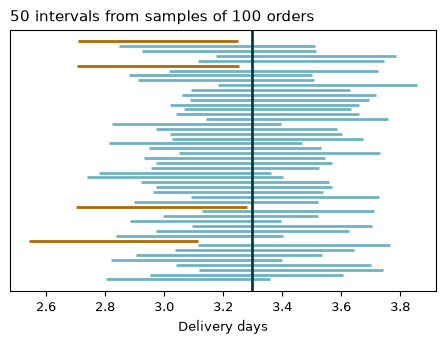

In [20]:
first = slice(0, 50)
colors = np.where(caught[first], '#6fb3c2', '#b26a00')
fig, ax = plt.subplots()
ax.hlines(np.arange(50), lows[first], highs[first], colors=colors)
ax.axvline(true_mean, color='#0b3a47')
ax.set_title('50 intervals from samples of 100 orders')
ax.set_xlabel('Delivery days')
ax.set_yticks([])
plt.show()

In [21]:
true_amount = amounts.mean()
rng = np.random.default_rng(42)
hits = 0
for _ in range(1000):
    one_sample = amounts.sample(50, random_state=rng)
    low, high = stats.t.interval(0.95, df=49, loc=one_sample.mean(),
                                 scale=stats.sem(one_sample))
    hits += low <= true_amount <= high
print(f'Caught the true average: {hits} of 1,000')

Caught the true average: 811 of 1,000


### The shaded band in `sns.regplot()`

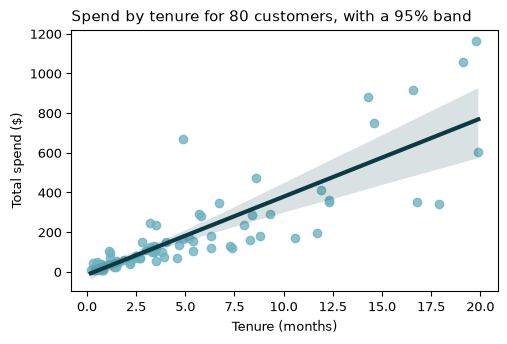

In [22]:
some_customers = customers.sample(80, random_state=42)
spend = orders.groupby('customer_id')['amount'].sum()
some_customers['total_spend'] = some_customers['customer_id'].map(spend)

ax = sns.regplot(data=some_customers, x='tenure_months',
                 y='total_spend', seed=42, color='#6fb3c2',
                 line_kws={'color': '#0b3a47'})
ax.set_title('Spend by tenure for 80 customers, with a 95% band')
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Total spend ($)')
plt.show()

## 12.6 The Bootstrap

### The bootstrap by hand

In [23]:
rng = np.random.default_rng(42)
boot_medians = []
for _ in range(1000):
    resample = rng.choice(amounts, size=len(amounts))
    boot_medians.append(np.median(resample))
print(f'Median of the sample: ${amounts.median():.2f}')
print(np.percentile(boot_medians, [2.5, 97.5]).round(2))

Median of the sample: $19.26
[18.84 19.61]


### `stats.bootstrap()`

In [24]:
rng = np.random.default_rng(42)
median_boot = stats.bootstrap((amounts,), np.median, rng=rng)
ci = median_boot.confidence_interval
print(f'confidence_interval: {ci.low:.2f} to {ci.high:.2f}')
print(f'standard_error: {median_boot.standard_error:.3f}')
print(f'resamples: {len(median_boot.bootstrap_distribution):,}')

confidence_interval: 18.84 to 19.57
standard_error: 0.186
resamples: 9,999


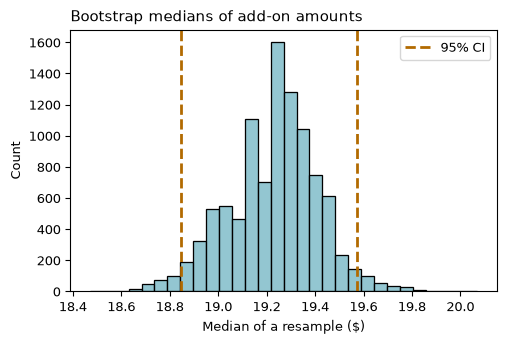

In [25]:
ax = sns.histplot(median_boot.bootstrap_distribution, bins=30,
                  color='#6fb3c2')
ax.axvline(ci.low, color='#b26a00', linestyle='--', label='95% CI')
ax.axvline(ci.high, color='#b26a00', linestyle='--')
ax.legend()
ax.set_title('Bootstrap medians of add-on amounts')
ax.set_xlabel('Median of a resample ($)')
plt.show()

In [26]:
def promoter_share(scores):
    return np.mean(scores >= 9)

scores = survey['recommend_score'].to_numpy()
rng = np.random.default_rng(42)
promoter_boot = stats.bootstrap((scores,), promoter_share, rng=rng)
promoter_ci = promoter_boot.confidence_interval
print(f'Scored 9 or 10: {promoter_share(scores):.1%}, '
      f'95% CI {promoter_ci.low:.1%} to {promoter_ci.high:.1%}')

Scored 9 or 10: 20.3%, 95% CI 16.9% to 23.7%


## 12.7 Biased Samples

### Survivorship bias in the survey

In [27]:
customers['replied'] = customers['customer_id'].isin(
    survey['customer_id'])
respondents = customers[customers['replied']]
print(f"Tenure, all customers: "
      f"{customers['tenure_months'].median():.1f} months (median)")
print(f"Tenure, respondents:   "
      f"{respondents['tenure_months'].median():.1f} months (median)")

Tenure, all customers: 3.4 months (median)
Tenure, respondents:   11.4 months (median)


In [28]:
plan_mix = pd.DataFrame({
    'All customers': customers['plan'].value_counts(normalize=True),
    'Respondents': respondents['plan'].value_counts(normalize=True),
})
plan_mix.round(3)

,All customers,Respondents
plan,,
Basic,0.448,0.250
Premium,0.193,0.308
Standard,0.359,0.442


In [29]:
cancellations['reason'].value_counts(normalize=True).round(3)

reason
Too expensive        0.273
Too much coffee      0.206
Other                0.190
Taste                0.180
Delivery problems    0.150
Name: proportion, dtype: float64

### Response bias

In [30]:
sent = pd.Timestamp('2025-11-01')
invited = customers[(customers['signup_date'] < sent)
                    & ~(customers['cancel_date'] < sent)].copy()
invited['months_by_nov'] = (
    (sent - invited['signup_date']).dt.days / 30.44)
print(f"First reply: {survey['response_date'].min().date()}")
print(f"{len(invited):,} invited, {invited['replied'].sum()} replied "
      f"({invited['replied'].mean():.1%})")

First reply: 2025-11-03
1,586 invited, 532 replied (33.5%)


In [31]:
bands = pd.cut(invited['months_by_nov'], bins=[0, 3, 6, 12, 24],
               labels=['0-3', '3-6', '6-12', '12-24'])
reply_rate = invited.groupby(bands)['replied'].agg(['mean', 'count'])
reply_rate.round(3)

,mean,count
months_by_nov,,
0-3,0.136,513
3-6,0.268,317
6-12,0.417,446
12-24,0.616,310


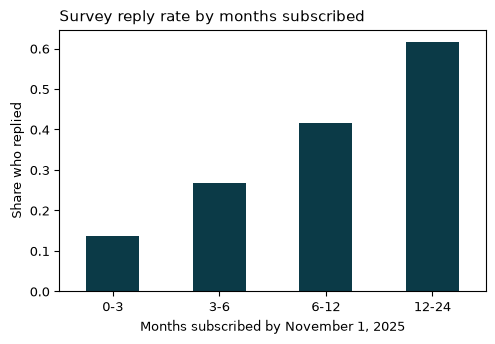

In [32]:
ax = reply_rate['mean'].plot.bar(color='#0b3a47', rot=0)
ax.set_title('Survey reply rate by months subscribed')
ax.set_xlabel('Months subscribed by November 1, 2025')
ax.set_ylabel('Share who replied')
plt.show()

### What bias does to the answer

In [33]:
survey_tenure = survey.merge(
    invited[['customer_id', 'months_by_nov']], on='customer_id',
    validate='one_to_one')
survey_bands = pd.cut(survey_tenure['months_by_nov'],
                      bins=[0, 3, 6, 12, 24],
                      labels=['0-3', '3-6', '6-12', '12-24'])
(survey_tenure.groupby(survey_bands)['satisfaction']
    .agg(['mean', 'count'])
    .round(2))

,mean,count
months_by_nov,,
0-3,3.70,70
3-6,3.76,85
6-12,3.59,186
12-24,3.59,191
